In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from google.colab import files

uploaded = files.upload()
fname = list(uploaded.keys())[0]
df = pd.read_csv(fname, encoding='latin-1', low_memory=False)
df.head()

Saving InternetSales.csv to InternetSales (3).csv


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [8]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
monthly = df.set_index('OrderDate')['SalesAmount'].resample('MS').sum()
monthly = monthly['2011-01-01':'2013-12-01']

In [9]:
print(df['SalesAmount'].describe())
top = df.groupby('EnglishProductName')['SalesAmount'].sum().sort_values(ascending=False)
print(top.head(10))
print("Top product:", top.idxmax(), round(top.max(), 2))

count    60398.000000
mean       486.086911
std        928.489892
min          2.290000
25%          7.950000
50%         29.990000
75%        539.990000
max       3578.270000
Name: SalesAmount, dtype: float64
EnglishProductName
Mountain-200 Black, 46     1.373470e+06
Mountain-200 Black, 42     1.363142e+06
Mountain-200 Silver, 38    1.339463e+06
Mountain-200 Silver, 46    1.301100e+06
Mountain-200 Black, 38     1.294866e+06
Mountain-200 Silver, 42    1.257435e+06
Road-150 Red, 48           1.205877e+06
Road-150 Red, 62           1.202299e+06
Road-150 Red, 52           1.080638e+06
Road-150 Red, 56           1.055590e+06
Name: SalesAmount, dtype: float64
Top product: Mountain-200 Black, 46 1373469.55


In [10]:
X = np.arange(len(monthly)).reshape(-1, 1)
model = LinearRegression().fit(X, monthly.values)
trend = model.predict(X)

future_X = np.arange(len(monthly), len(monthly) + 60).reshape(-1, 1)
future_dates = pd.date_range(monthly.index[-1] + pd.DateOffset(months=1),
                             periods=60, freq='MS')
forecast = pd.Series(model.predict(future_X), index=future_dates)

print(forecast.resample('YS').sum())

2014-01-01    1.937375e+07
2015-01-01    2.418237e+07
2016-01-01    2.899099e+07
2017-01-01    3.379960e+07
2018-01-01    3.860822e+07
Freq: YS-JAN, dtype: float64


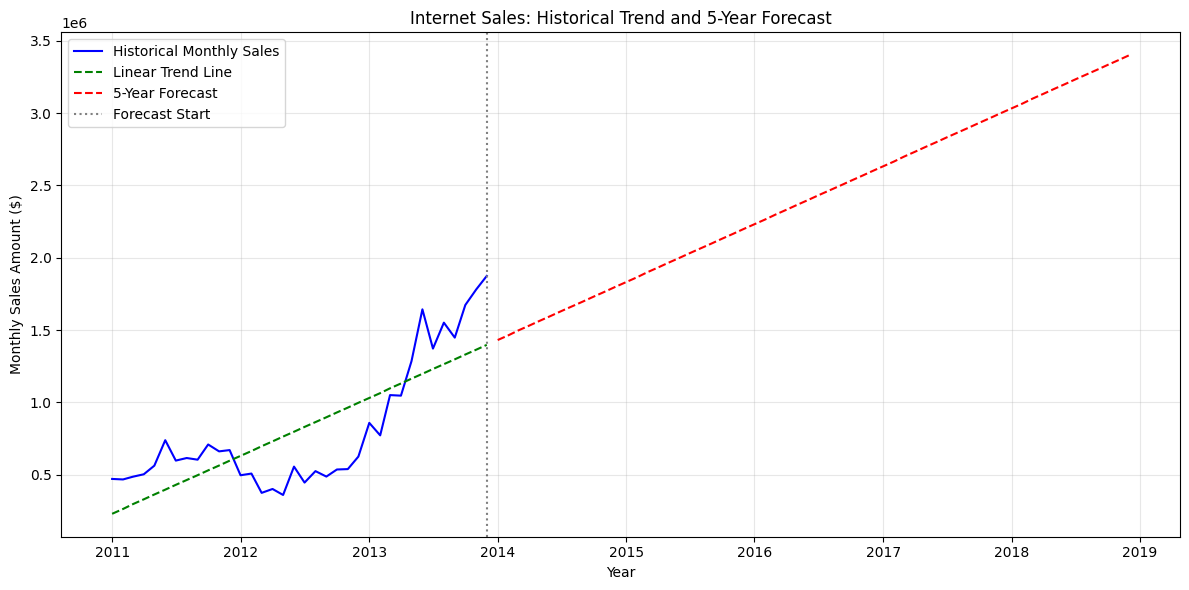

In [11]:
plt.figure(figsize=(12, 6))
plt.plot(monthly.index, monthly.values, label='Historical Monthly Sales', color='blue')
plt.plot(monthly.index, trend, label='Linear Trend Line', color='green', linestyle='--')
plt.plot(forecast.index, forecast.values, label='5-Year Forecast', color='red', linestyle='--')
plt.axvline(monthly.index[-1], color='gray', linestyle=':', label='Forecast Start')
plt.title('Internet Sales: Historical Trend and 5-Year Forecast')
plt.xlabel('Year')
plt.ylabel('Monthly Sales Amount ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Based on summary statistics, Mountain-200 Black, 46 generated the highest total sales (USD 1,373,469.55). Monthly sales show an upward linear trend, and the model forecasts annual sales rising from about USD 19.4M in 2014 to USD 38.6M in 2018.

Limitations: The linear model does not account for seasonality, and Dec 2010 and Jan 2014 were excluded as partial months. The data set is fictitious, so these results are for demonstration only.